<a href="https://colab.research.google.com/github/yami-stack/machine_learning/blob/main/Experiments-ML/CSL701_CE48Machine_Learning_Lab_Exp10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name :Yash Manohar Tawate

Batch :CE03

Roll Number :CE48



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [1]:
# Task 1: Import Libraries and Load Dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Manually upload the CSV file in Google Colab
from google.colab import files

uploaded = files.upload()

# Get the uploaded CSV filename
csv_file = next(
    (name for name in uploaded if name.lower().endswith(".csv")),
    None
)

if csv_file is None:
    raise ValueError("Please upload a CSV file.")

# Load dataset
df = pd.read_csv(csv_file)

# Display dataset details
print("Dataset loaded successfully!")
print("\nFirst five rows:")
display(df.head())

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Saving Mall_Customers.csv to Mall_Customers.csv
Dataset loaded successfully!

First five rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset shape: (200, 5)

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [2]:
# Task 2: Feature Selection and Standardization

# Select the required features
features = [
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

# Check that the required columns exist
missing_columns = [col for col in features if col not in df.columns]

if missing_columns:
    raise ValueError(
        f"Required columns not found: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )

# Keep only rows with valid values in the selected features
X = df[features].apply(pd.to_numeric, errors="coerce")
valid_rows = X.notna().all(axis=1)

X = X.loc[valid_rows].copy()
df_clean = df.loc[valid_rows].copy()

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original features:")
display(X.head())

print("\nStandardized features:")
display(pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
).head())

print("\nScaled data shape:", X_scaled.shape)

Original features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Standardized features:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Scaled data shape: (200, 2)


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

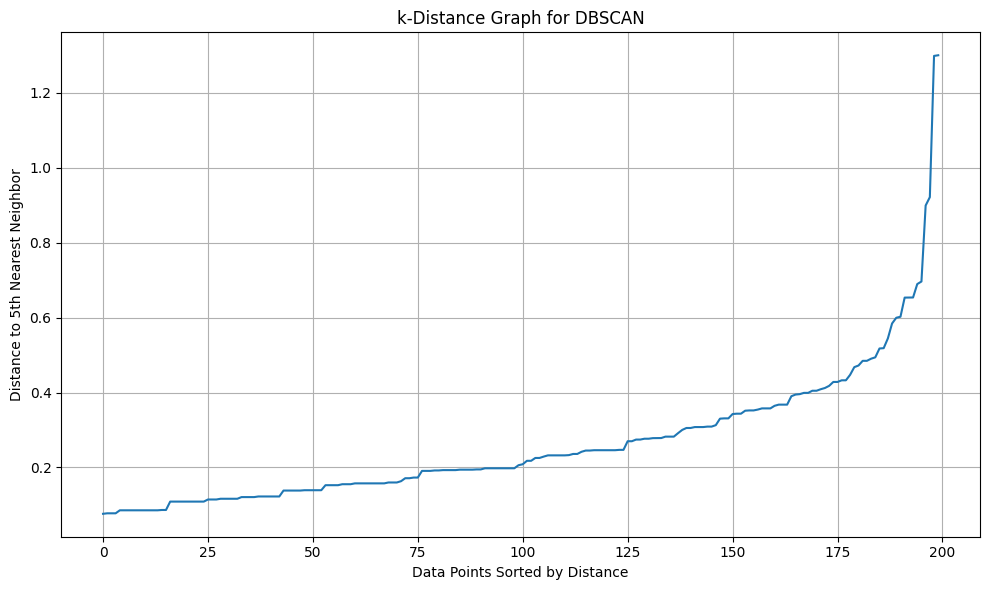

Suggested min_samples: 5
Inspect the graph's elbow to choose eps.


In [3]:
# Task 3: Hyperparameter Selection via k-Distance Graph

# Number of neighbors to consider
min_samples = 5

# Calculate nearest-neighbor distances
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Distance to the kth nearest neighbor
k_distances = distances[:, min_samples - 1]

# Sort distances in ascending order
k_distances_sorted = np.sort(k_distances)

# Plot the k-distance graph
plt.figure(figsize=(10, 6))
plt.plot(k_distances_sorted)
plt.xlabel("Data Points Sorted by Distance")
plt.ylabel(f"Distance to {min_samples}th Nearest Neighbor")
plt.title("k-Distance Graph for DBSCAN")
plt.grid(True)
plt.tight_layout()
plt.show()

print("Suggested min_samples:", min_samples)
print("Inspect the graph's elbow to choose eps.")

# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

In [4]:
# Task 4: Implement DBSCAN Clustering

# Initial eps value; adjust it based on Task 3's graph
eps_value = 0.6

dbscan = DBSCAN(
    eps=eps_value,
    min_samples=min_samples
)

# Fit model and predict cluster labels
cluster_labels = dbscan.fit_predict(X_scaled)

# Add cluster labels to the cleaned dataset
df_clean["Cluster"] = cluster_labels

print("DBSCAN clustering completed.")
print("\nFirst five rows with cluster labels:")
display(df_clean.head())

print("\nCluster labels found:")
print(np.unique(cluster_labels))

DBSCAN clustering completed.

First five rows with cluster labels:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0



Cluster labels found:
[-1  0]


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [5]:
# Task 5: Evaluate DBSCAN Clustering

# Get cluster labels
labels = df_clean["Cluster"]

# Identify noise points (-1)
noise_count = (labels == -1).sum()

# Count clusters excluding noise
n_clusters = len(set(labels) - {-1})

print("Number of clusters:", n_clusters)
print("Number of noise points:", noise_count)
print("Total data points:", len(labels))

# Calculate Silhouette Score
# Exclude noise points for cluster-quality evaluation
non_noise_mask = labels != -1
X_non_noise = X_scaled[non_noise_mask]
labels_non_noise = labels[non_noise_mask]

if (
    len(np.unique(labels_non_noise)) >= 2
    and len(np.unique(labels_non_noise)) < len(labels_non_noise)
):
    score = silhouette_score(X_non_noise, labels_non_noise)
    print(f"Silhouette Score: {score:.4f}")
else:
    print(
        "Silhouette Score cannot be calculated: "
        "at least two non-noise clusters are required."
    )

Number of clusters: 1
Number of noise points: 5
Total data points: 200
Silhouette Score cannot be calculated: at least two non-noise clusters are required.


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

Dataset with cluster assignments:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0
5,6,Female,22,17,76,0
6,7,Female,35,18,6,0
7,8,Female,23,18,94,0
8,9,Male,64,19,3,0
9,10,Female,30,19,72,0



Number of customers in each cluster:
Cluster
-1      5
 0    195
Name: count, dtype: int64

Average Annual Income and Spending Score per Cluster:


,Annual Income (k$),Spending Score (1-100)
Cluster,,
-1,129.2,43.80
0,58.8,50.36


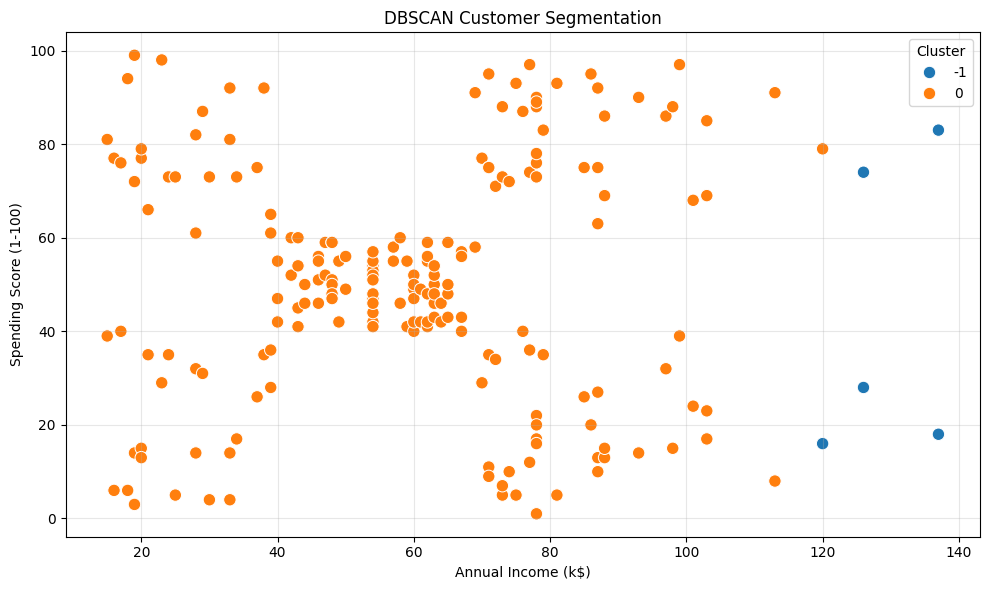

In [6]:
# Task 6: Analyze Results and Cluster Statistics

# Display the dataset with cluster labels
print("Dataset with cluster assignments:")
display(df_clean.head(10))

# Count points in each cluster, including noise
print("\nNumber of customers in each cluster:")
print(df_clean["Cluster"].value_counts().sort_index())

# Calculate mean statistics for each cluster
cluster_stats = df_clean.groupby("Cluster")[features].mean()

print("\nAverage Annual Income and Spending Score per Cluster:")
display(cluster_stats.round(2))

# Visualize the clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=80
)

plt.title("DBSCAN Customer Segmentation")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.